In [2]:
# ==============================================================================
# CELL 1: Imports and Setup
# ==============================================================================
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import random
import pickle
import torch
import warnings

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from dataset_skin import get_federated_dataloaders
from models_skin import get_resnet18_classifier
from utils_skin import calculate_entropy, compute_dynamic_mu, evaluate_resnet
from client_skin import train_client_resnet_dp
from client_skin import train_client_resnet_nodp
from server_skin import federated_averaging

In [3]:
warnings.filterwarnings('ignore')

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Device Name: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"PyTorch Version: {torch.__version__}")

CUDA Available: True
Device Name: NVIDIA GeForce RTX 3050 Laptop GPU
PyTorch Version: 2.6.0+cu124


In [5]:
def set_seed(seed=42):
    """Locks all random number generators for exact reproducibility."""
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [6]:
# Lock the universe to Seed 42
set_seed(42)

In [7]:
# # ==============================================================================
# # CELL 2: Data Loading & Hybrid Weight Calculation (alpha = 0.1)
# # ==============================================================================
# num_clients = 5
# # UPDATED: alpha=0.1 forces extreme Non-IID distribution
# client_loaders, test_loader = get_federated_dataloaders(num_clients=num_clients, alpha=0.1, batch_size=32)

# class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

# entropies = []
# clinic_distributions = []
# sample_counts = [] 

# for i, loader in enumerate(client_loaders):
#     labels = torch.cat([y for _, y in loader]).squeeze().numpy()
#     entropies.append(calculate_entropy(labels, num_classes=7))
    
#     counts = np.bincount(labels, minlength=7)
#     clinic_distributions.append(counts)
#     sample_counts.append(len(labels)) 

# dynamic_mus = compute_dynamic_mu(entropies, num_classes=7, mu_base=0.01, lambda_scale=1.5)

# # Calculate the Hybrid FedShield Weights (Entropy * Sample Size)
# fedshield_weights = [e * n for e, n in zip(entropies, sample_counts)]

# # Display Formatted Matrix
# df_dist = pd.DataFrame(clinic_distributions, columns=[f"{c} (Class {idx})" for idx, c in enumerate(class_names)])
# df_dist.insert(0, "Clinic", [f"Clinic {i+1}" for i in range(num_clients)])
# df_dist["Total Samples"] = sample_counts
# df_dist["Entropy (H_k)"] = [f"{h:.4f}" for h in entropies]
# df_dist["Assigned mu_k"] = [f"{m:.4f}" for m in dynamic_mus]
# df_dist["Hybrid Weight"] = [f"{w:.2f}" for w in fedshield_weights] 

# print("\n========================= CLINIC CLASS DISTRIBUTION MATRIX =========================")
# print(df_dist.to_string(index=False))
# print("====================================================================================\n")

# Exponential Hybrid Weighting
num_clients = 5
client_loaders, test_loader = get_federated_dataloaders(num_clients=num_clients, alpha=0.1, batch_size=32)

class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

entropies = []
clinic_distributions = []
sample_counts = [] 

for i, loader in enumerate(client_loaders):
    labels = torch.cat([y for _, y in loader]).squeeze().numpy()
    entropies.append(calculate_entropy(labels, num_classes=7))
    
    counts = np.bincount(labels, minlength=7)
    clinic_distributions.append(counts)
    sample_counts.append(len(labels)) 

# FIX 1: Lower lambda_scale from 1.5 to 0.5 to prevent paralyzing skewed clinics
dynamic_mus = compute_dynamic_mu(entropies, num_classes=7, mu_base=0.01, lambda_scale=0.5)

# FIX 2: Exponential Hybrid Weights (N_k * e^(H_k))
# fedshield_weights = [n * np.exp(e) for e, n in zip(entropies, sample_counts)]
# THE FINAL FIX: Sub-linear (Square-Root) Volume Scaling 
# fedshield_weights = [np.sqrt(n) * np.exp(e) for e, n in zip(entropies, sample_counts)]
# THE FINAL ARCHITECTURE: Pure Exponential Entropy Weighting
fedshield_weights = [np.exp(e) for e in entropies]

# Display Formatted Matrix
df_dist = pd.DataFrame(clinic_distributions, columns=[f"{c} (Class {idx})" for idx, c in enumerate(class_names)])
df_dist.insert(0, "Clinic", [f"Clinic {i+1}" for i in range(num_clients)])
df_dist["Total Samples"] = sample_counts
df_dist["Entropy (H_k)"] = [f"{h:.4f}" for h in entropies]
df_dist["Assigned mu_k"] = [f"{m:.4f}" for m in dynamic_mus]
df_dist["Exp Hybrid Weight"] = [f"{w:.2f}" for w in fedshield_weights] 

print("\n========================= CLINIC CLASS DISTRIBUTION MATRIX =========================")
print(df_dist.to_string(index=False))
print("====================================================================================\n")

Downloading/Loading DermaMNIST dataset...
Data Partitioning Complete across 5 Virtual Clinics.

========================= CLINIC CLASS DISTRIBUTION MATRIX =========================
  Clinic  akiec (Class 0)  bcc (Class 1)  bkl (Class 2)  df (Class 3)  mel (Class 4)  nv (Class 5)  vasc (Class 6)  Total Samples Entropy (H_k) Assigned mu_k Exp Hybrid Weight
Clinic 1                0            347              0             0             27            17              46            437        1.0364        0.0189              2.82
Clinic 2                1              0              0             0            189             0              52            242        0.7879        0.0201              2.20
Clinic 3                0             11            670            73            463             0               0           1217        1.3094        0.0175              3.70
Clinic 4              226              0              1             6             99             0               1 

In [8]:
# ==============================================================================
# CELL 3: DP Training Function
# ==============================================================================
'''
def run_resnet_experiment(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING PHASE 2: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_eps = 0.0

    for round_num in range(num_rounds):
        client_models = []
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, eps = train_client_resnet_dp(
                local_model=local_model,
                global_model=global_model,
                train_loader=client_loaders[i],
                mu=current_mu,
                device=device,
                epochs=2, 
                lr=0.1, 
                noise_multiplier=1.2,
                max_grad_norm=1.0
            )
            client_models.append(trained_model)
            final_eps = eps

        # Server Aggregation
        if algorithm_name == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
        
        acc, auc = evaluate_resnet(global_model, test_loader, device)
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"Final {algorithm_name} AUC: {auc_history[-1]:.4f} | Epsilon: {final_eps:.2f}")
    return auc_history, global_model
'''
def run_resnet_experiment(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING PHASE 2: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_eps = 0.0
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, eps = train_client_resnet_dp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1, 
                noise_multiplier=1.2, max_grad_norm=1.0
            )
            client_models.append(trained_model)
            final_eps = eps

        if algorithm_name == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=sample_counts)  
        
        # Grab predictions only on the final round
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal {algorithm_name} AUC: {auc_history[-1]:.4f} | Epsilon: {final_eps:.2f}")
    
    # NEW: Print full 7-class report and plot the 7x7 matrix
    class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    print(f"\n--- {algorithm_name} (DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} DP Confusion Matrix")
    plt.xticks(rotation=45) 
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model


========== STARTING PHASE 2: FedAvg ==========
Round 01/15 | Global Test AUC: 0.5192 | Accuracy: 0.6554
Round 02/15 | Global Test AUC: 0.5686 | Accuracy: 0.6095
Round 03/15 | Global Test AUC: 0.5578 | Accuracy: 0.5676
Round 04/15 | Global Test AUC: 0.5579 | Accuracy: 0.5696
Round 05/15 | Global Test AUC: 0.5568 | Accuracy: 0.6045
Round 06/15 | Global Test AUC: 0.5504 | Accuracy: 0.5726
Round 07/15 | Global Test AUC: 0.5445 | Accuracy: 0.6105
Round 08/15 | Global Test AUC: 0.5621 | Accuracy: 0.6105
Round 09/15 | Global Test AUC: 0.5645 | Accuracy: 0.6379
Round 10/15 | Global Test AUC: 0.5643 | Accuracy: 0.5796
Round 11/15 | Global Test AUC: 0.5603 | Accuracy: 0.6429
Round 12/15 | Global Test AUC: 0.5613 | Accuracy: 0.6195
Round 13/15 | Global Test AUC: 0.5701 | Accuracy: 0.6329
Round 14/15 | Global Test AUC: 0.5763 | Accuracy: 0.6259
Round 15/15 | Global Test AUC: 0.5629 | Accuracy: 0.6110

Final FedAvg AUC: 0.5629 | Epsilon: 0.47

--- FedAvg (DP) Classification Report ---
            

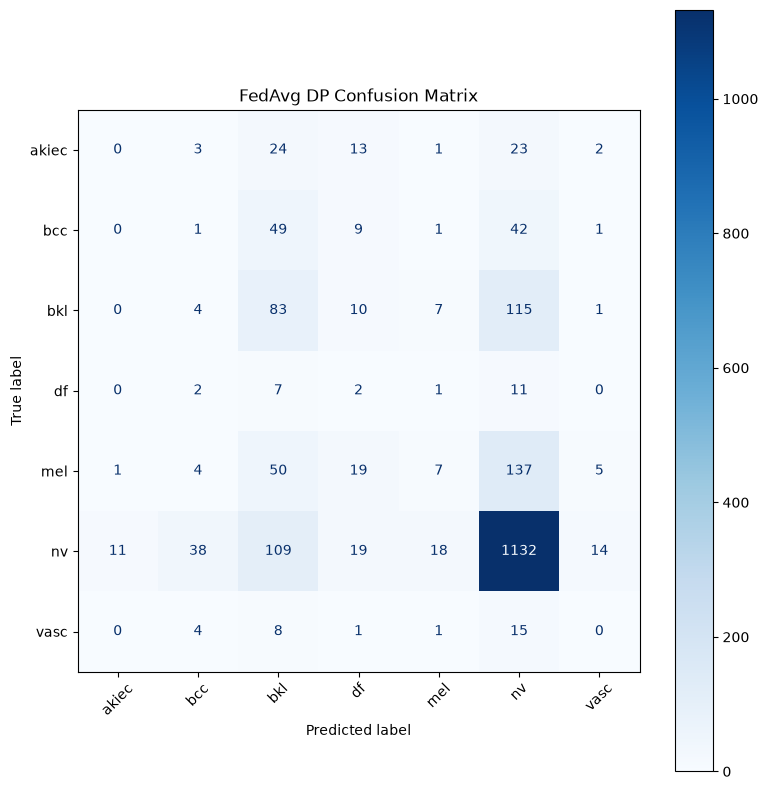

In [9]:
# ==============================================================================
# CELL 4: Run DP Experiments & Plot
# ==============================================================================
auc_fedavg, _ = run_resnet_experiment("FedAvg", num_rounds=15)


========== STARTING PHASE 2: FedProx ==========
Round 01/15 | Global Test AUC: 0.5149 | Accuracy: 0.6658
Round 02/15 | Global Test AUC: 0.5332 | Accuracy: 0.5711
Round 03/15 | Global Test AUC: 0.5367 | Accuracy: 0.6389
Round 04/15 | Global Test AUC: 0.5491 | Accuracy: 0.6085
Round 05/15 | Global Test AUC: 0.5485 | Accuracy: 0.6155
Round 06/15 | Global Test AUC: 0.5368 | Accuracy: 0.5781
Round 07/15 | Global Test AUC: 0.5522 | Accuracy: 0.5875
Round 08/15 | Global Test AUC: 0.5514 | Accuracy: 0.6130
Round 09/15 | Global Test AUC: 0.5485 | Accuracy: 0.6080
Round 10/15 | Global Test AUC: 0.5476 | Accuracy: 0.6374
Round 11/15 | Global Test AUC: 0.5528 | Accuracy: 0.5965
Round 12/15 | Global Test AUC: 0.5612 | Accuracy: 0.6165
Round 13/15 | Global Test AUC: 0.5450 | Accuracy: 0.6115
Round 14/15 | Global Test AUC: 0.5439 | Accuracy: 0.6229
Round 15/15 | Global Test AUC: 0.5454 | Accuracy: 0.5965

Final FedProx AUC: 0.5454 | Epsilon: 0.47

--- FedProx (DP) Classification Report ---
         

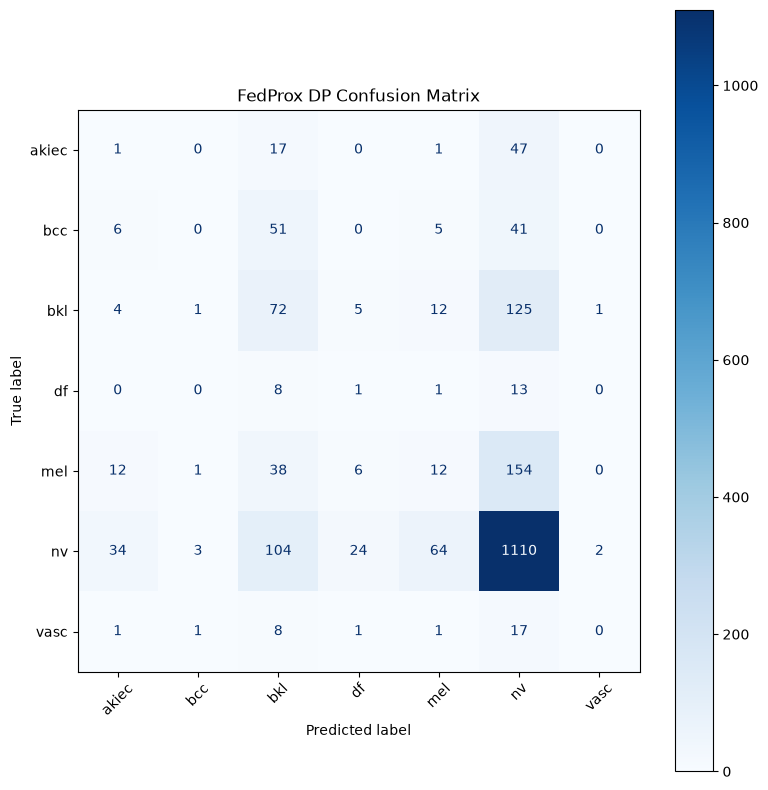

In [10]:
auc_fedprox, _ = run_resnet_experiment("FedProx", num_rounds=15)


========== STARTING PHASE 2: FedShield ==========
Round 01/15 | Global Test AUC: 0.5877 | Accuracy: 0.1342
Round 02/15 | Global Test AUC: 0.6199 | Accuracy: 0.3606
Round 03/15 | Global Test AUC: 0.6141 | Accuracy: 0.1382
Round 04/15 | Global Test AUC: 0.6241 | Accuracy: 0.2474
Round 05/15 | Global Test AUC: 0.6406 | Accuracy: 0.1501
Round 06/15 | Global Test AUC: 0.6431 | Accuracy: 0.3965
Round 07/15 | Global Test AUC: 0.6461 | Accuracy: 0.3980
Round 08/15 | Global Test AUC: 0.6582 | Accuracy: 0.2399
Round 09/15 | Global Test AUC: 0.6712 | Accuracy: 0.3506
Round 10/15 | Global Test AUC: 0.6664 | Accuracy: 0.2045
Round 11/15 | Global Test AUC: 0.6724 | Accuracy: 0.3456
Round 12/15 | Global Test AUC: 0.6719 | Accuracy: 0.2065
Round 13/15 | Global Test AUC: 0.6810 | Accuracy: 0.3576
Round 14/15 | Global Test AUC: 0.6688 | Accuracy: 0.2589
Round 15/15 | Global Test AUC: 0.6689 | Accuracy: 0.3995

Final FedShield AUC: 0.6689 | Epsilon: 0.47

--- FedShield (DP) Classification Report ---
   

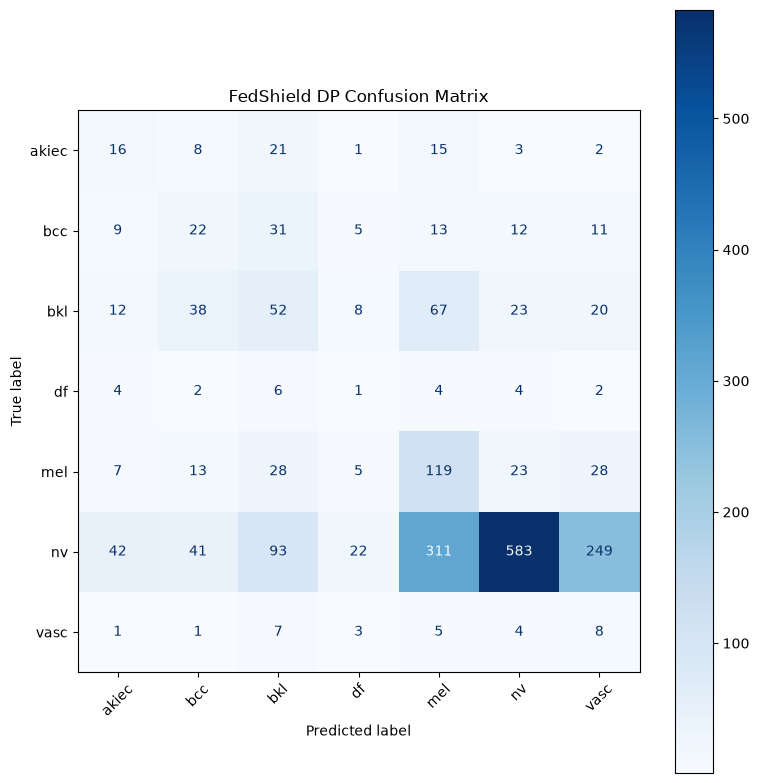

In [11]:
auc_fedshield, final_model = run_resnet_experiment("FedShield", num_rounds=15)

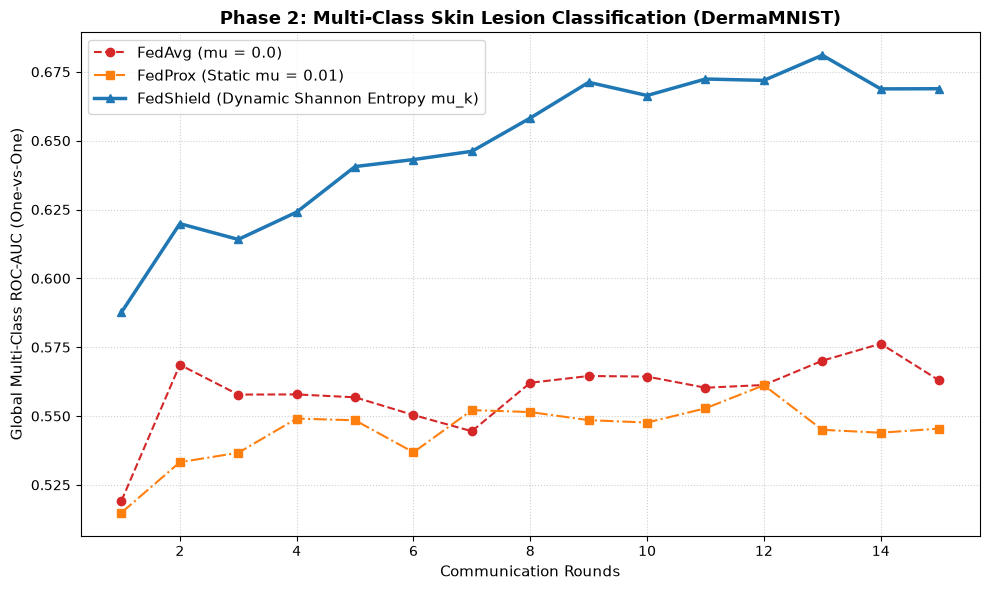

In [12]:
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, auc_fedavg, marker='o', linestyle='--', color='tab:red', label='FedAvg (mu = 0.0)')
plt.plot(rounds_range, auc_fedprox, marker='s', linestyle='-.', color='tab:orange', label='FedProx (Static mu = 0.01)')
plt.plot(rounds_range, auc_fedshield, marker='^', linestyle='-', color='tab:blue', linewidth=2.5, label='FedShield (Dynamic Shannon Entropy mu_k)')

plt.title("Phase 2: Multi-Class Skin Lesion Classification (DermaMNIST)", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global Multi-Class ROC-AUC (One-vs-One)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [13]:
torch.save(final_model.state_dict(), "fedshield_resnet18_dermamnist_2_nk_by_N.pth")
print("Trained FedShield Global Model successfully saved to 'fedshield_resnet18_dermamnist_2_nk_by_N.pth'")

Trained FedShield Global Model successfully saved to 'fedshield_resnet18_dermamnist_2_nk_by_N.pth'


In [14]:
# ==============================================================================
# CELL 5: Non-DP Training Function (Ablation Study)
# ==============================================================================
'''
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []

    for round_num in range(num_rounds):
        client_models = []
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model,
                global_model=global_model,
                train_loader=client_loaders[i],
                mu=current_mu,
                device=device,
                epochs=2, 
                lr=0.1
            )
            client_models.append(trained_model)

        # UPDATED: No Server-Side Entropy for Non-DP Ablation.
        global_model = federated_averaging(global_model, client_models, weights=None)
        
        acc, auc = evaluate_resnet(global_model, test_loader, device)
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"Final Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    return auc_history, global_model
    '''
"""
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1
            )
            client_models.append(trained_model)

        global_model = federated_averaging(global_model, client_models, weights=None)
        
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    
    # NEW: Print full 7-class report and plot the 7x7 matrix
    class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    print(f"\n--- {algorithm_name} (No-DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Greens, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} No-DP Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model
"""
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name in ["FedShield_Local", "FedShield_Full"]:
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1
            )
            client_models.append(trained_model)

        # NEW: Apply Server weights ONLY for FedShield_Full
        if algorithm_name == "FedShield_Full":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=sample_counts)  # Use sample counts for FedAvg, FedProx, and FedShield_Local
        
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    
    class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    print(f"\n--- {algorithm_name} (No-DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Greens, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} No-DP Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model

Starting Non-DP Ablation Study...

========== STARTING NON-DP PHASE: FedAvg ==========
Round 01/15 | Global Test AUC: 0.5971 | Accuracy: 0.6833
Round 02/15 | Global Test AUC: 0.7041 | Accuracy: 0.1167
Round 03/15 | Global Test AUC: 0.5199 | Accuracy: 0.6703
Round 04/15 | Global Test AUC: 0.6301 | Accuracy: 0.1152
Round 05/15 | Global Test AUC: 0.6131 | Accuracy: 0.6908
Round 06/15 | Global Test AUC: 0.6459 | Accuracy: 0.1147
Round 07/15 | Global Test AUC: 0.5627 | Accuracy: 0.6434
Round 08/15 | Global Test AUC: 0.7221 | Accuracy: 0.1556
Round 09/15 | Global Test AUC: 0.7259 | Accuracy: 0.6499
Round 10/15 | Global Test AUC: 0.7297 | Accuracy: 0.1726
Round 11/15 | Global Test AUC: 0.6455 | Accuracy: 0.6818
Round 12/15 | Global Test AUC: 0.7396 | Accuracy: 0.1047
Round 13/15 | Global Test AUC: 0.5502 | Accuracy: 0.6818
Round 14/15 | Global Test AUC: 0.6745 | Accuracy: 0.1167
Round 15/15 | Global Test AUC: 0.5511 | Accuracy: 0.6828

Final Non-DP FedAvg AUC: 0.5511

--- FedAvg (No-DP) Class

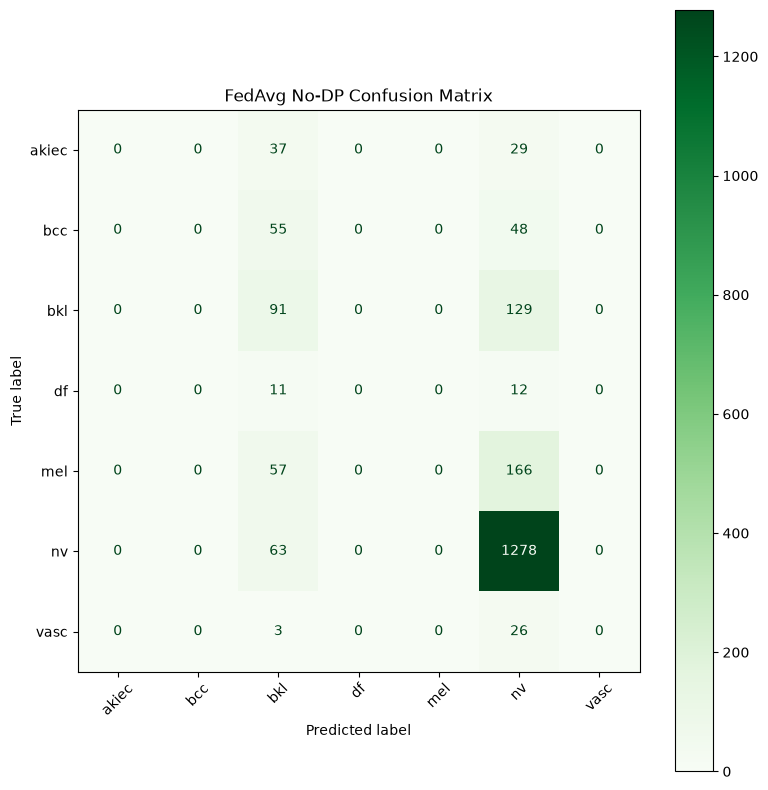

In [15]:
# ==============================================================================
# CELL 6: Run Non-DP Experiments
# ==============================================================================
print("Starting Non-DP Ablation Study...")
nodp_auc_fedavg, nodp_model_fedavg = run_resnet_experiment_nodp("FedAvg", num_rounds=15)



========== STARTING NON-DP PHASE: FedProx ==========
Round 01/15 | Global Test AUC: 0.6695 | Accuracy: 0.2504
Round 02/15 | Global Test AUC: 0.6558 | Accuracy: 0.1122
Round 03/15 | Global Test AUC: 0.7348 | Accuracy: 0.6918
Round 04/15 | Global Test AUC: 0.6656 | Accuracy: 0.1516
Round 05/15 | Global Test AUC: 0.7226 | Accuracy: 0.4204
Round 06/15 | Global Test AUC: 0.7143 | Accuracy: 0.2693
Round 07/15 | Global Test AUC: 0.7662 | Accuracy: 0.5800
Round 08/15 | Global Test AUC: 0.6857 | Accuracy: 0.6688
Round 09/15 | Global Test AUC: 0.7566 | Accuracy: 0.1272
Round 10/15 | Global Test AUC: 0.7418 | Accuracy: 0.6613
Round 11/15 | Global Test AUC: 0.7679 | Accuracy: 0.1566
Round 12/15 | Global Test AUC: 0.7289 | Accuracy: 0.6698
Round 13/15 | Global Test AUC: 0.7367 | Accuracy: 0.1352
Round 14/15 | Global Test AUC: 0.7733 | Accuracy: 0.6763
Round 15/15 | Global Test AUC: 0.7254 | Accuracy: 0.1546

Final Non-DP FedProx AUC: 0.7254

--- FedProx (No-DP) Classification Report ---
          

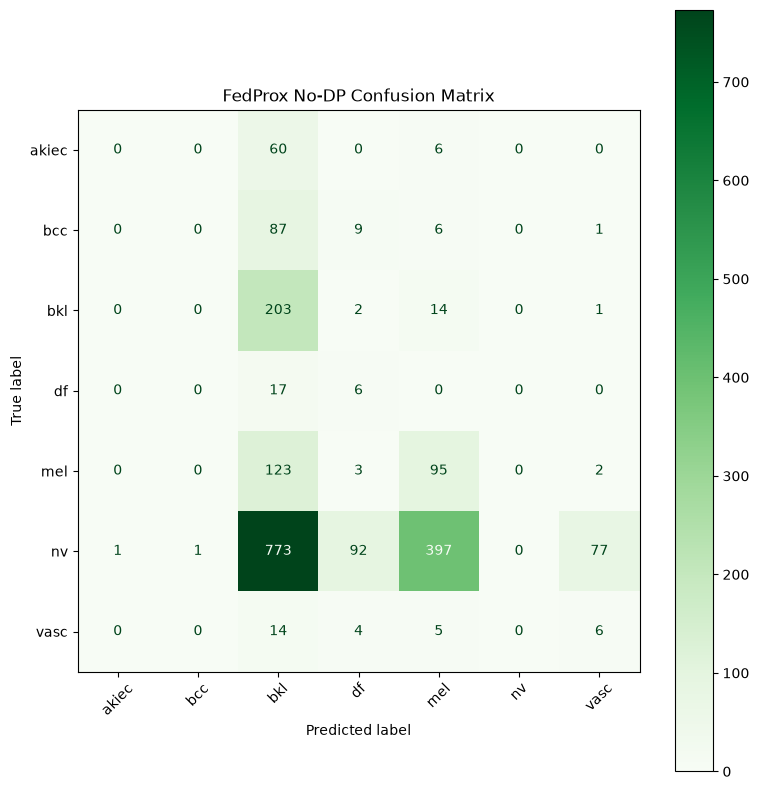

In [16]:
nodp_auc_fedprox, nodp_model_fedprox = run_resnet_experiment_nodp("FedProx", num_rounds=15)



========== STARTING NON-DP PHASE: FedShield_Local ==========
Round 01/15 | Global Test AUC: 0.5661 | Accuracy: 0.6688
Round 02/15 | Global Test AUC: 0.7016 | Accuracy: 0.1237
Round 03/15 | Global Test AUC: 0.7363 | Accuracy: 0.6868
Round 04/15 | Global Test AUC: 0.7435 | Accuracy: 0.1332
Round 05/15 | Global Test AUC: 0.7773 | Accuracy: 0.6683
Round 06/15 | Global Test AUC: 0.8005 | Accuracy: 0.2968
Round 07/15 | Global Test AUC: 0.7485 | Accuracy: 0.6469
Round 08/15 | Global Test AUC: 0.7644 | Accuracy: 0.6713
Round 09/15 | Global Test AUC: 0.7778 | Accuracy: 0.1392
Round 10/15 | Global Test AUC: 0.7830 | Accuracy: 0.5466
Round 11/15 | Global Test AUC: 0.8030 | Accuracy: 0.5112
Round 12/15 | Global Test AUC: 0.7812 | Accuracy: 0.4529
Round 13/15 | Global Test AUC: 0.7730 | Accuracy: 0.6848
Round 14/15 | Global Test AUC: 0.7945 | Accuracy: 0.1895
Round 15/15 | Global Test AUC: 0.7851 | Accuracy: 0.6000

Final Non-DP FedShield_Local AUC: 0.7851

--- FedShield_Local (No-DP) Classificati

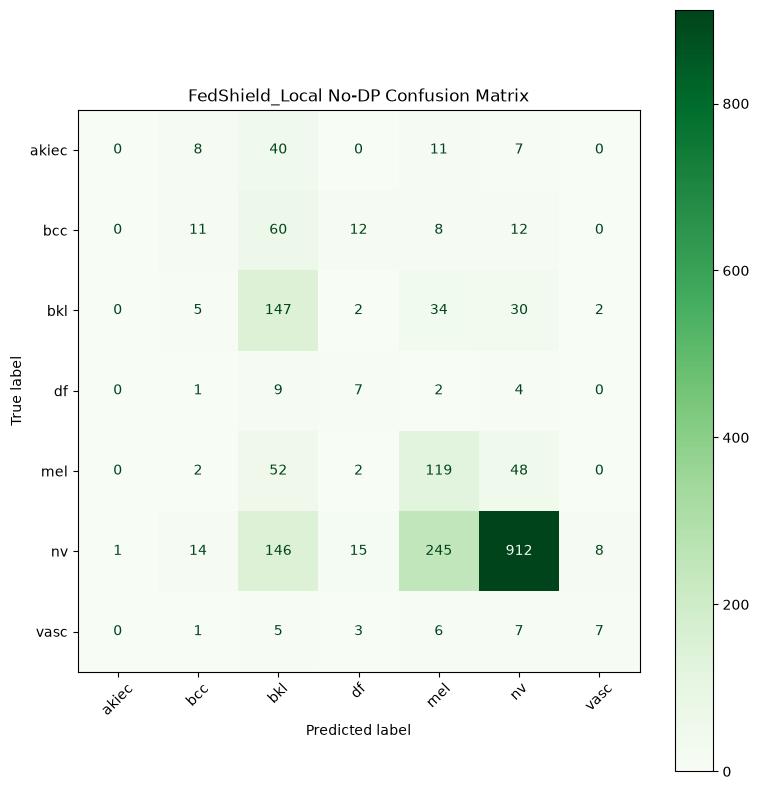

In [17]:
nodp_auc_fedshield_local, nodp_model_fedshield_local = run_resnet_experiment_nodp("FedShield_Local", num_rounds=15)


========== STARTING NON-DP PHASE: FedShield_Full ==========
Round 01/15 | Global Test AUC: 0.6410 | Accuracy: 0.1112
Round 02/15 | Global Test AUC: 0.7705 | Accuracy: 0.1277
Round 03/15 | Global Test AUC: 0.7641 | Accuracy: 0.1122
Round 04/15 | Global Test AUC: 0.7351 | Accuracy: 0.1152
Round 05/15 | Global Test AUC: 0.7619 | Accuracy: 0.3586
Round 06/15 | Global Test AUC: 0.7454 | Accuracy: 0.3845
Round 07/15 | Global Test AUC: 0.7959 | Accuracy: 0.3855
Round 08/15 | Global Test AUC: 0.7768 | Accuracy: 0.3102
Round 09/15 | Global Test AUC: 0.7461 | Accuracy: 0.1776
Round 10/15 | Global Test AUC: 0.8001 | Accuracy: 0.4269
Round 11/15 | Global Test AUC: 0.7994 | Accuracy: 0.1845
Round 12/15 | Global Test AUC: 0.7786 | Accuracy: 0.4828
Round 13/15 | Global Test AUC: 0.8035 | Accuracy: 0.2584
Round 14/15 | Global Test AUC: 0.7972 | Accuracy: 0.4414
Round 15/15 | Global Test AUC: 0.7851 | Accuracy: 0.2514

Final Non-DP FedShield_Full AUC: 0.7851

--- FedShield_Full (No-DP) Classification 

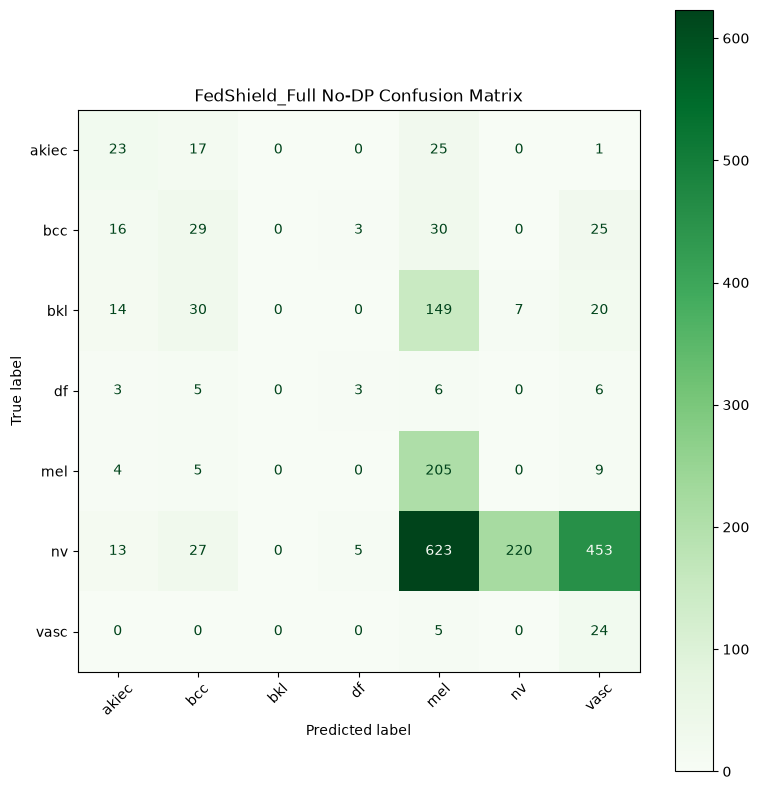

In [18]:
nodp_auc_fedshield_full, nodp_model_fedshield_full = run_resnet_experiment_nodp("FedShield_Full", num_rounds=15)

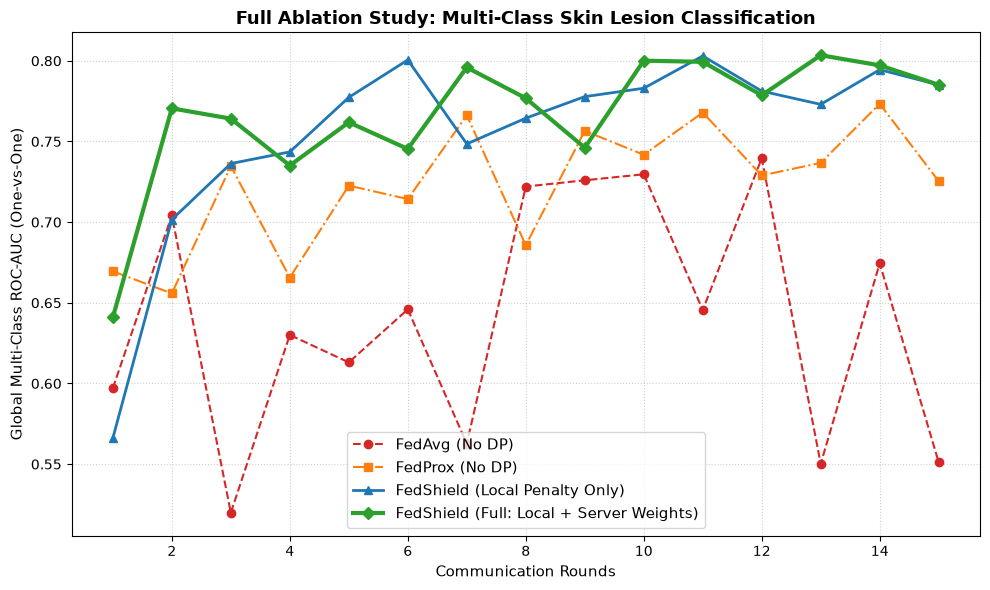

In [19]:
# ==============================================================================
# CELL 7: Plot Non-DP Ablation Study Results
# ==============================================================================
# Plot the 4-step Ablation Study
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, nodp_auc_fedavg, marker='o', linestyle='--', color='tab:red', label='FedAvg (No DP)')
plt.plot(rounds_range, nodp_auc_fedprox, marker='s', linestyle='-.', color='tab:orange', label='FedProx (No DP)')
plt.plot(rounds_range, nodp_auc_fedshield_local, marker='^', linestyle='-', color='tab:blue', linewidth=2, label='FedShield (Local Penalty Only)')
plt.plot(rounds_range, nodp_auc_fedshield_full, marker='D', linestyle='-', color='tab:green', linewidth=3, label='FedShield (Full: Local + Server Weights)')

plt.title("Full Ablation Study: Multi-Class Skin Lesion Classification", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global Multi-Class ROC-AUC (One-vs-One)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [20]:
"""
# 1. Bundle EVERYTHING (DP and Non-DP histories) into one master dictionary
full_context = {
    # DP Data
    "auc_fedshield": auc_fedshield,
    "auc_fedprox": auc_fedprox,
    "auc_fedavg": auc_fedavg,
    "entropies": entropies,
    "dynamic_mus": dynamic_mus,
    "fedshield_weights": fedshield_weights,
    "clinic_distributions": clinic_distributions,
    "sample_counts": sample_counts,
    
    # Non-DP Data
    "nodp_auc_fedavg": nodp_auc_fedavg,
    "nodp_auc_fedprox": nodp_auc_fedprox,
    "nodp_auc_fedshield": nodp_auc_fedshield
}

# 2. Save all the variables to a pickle file
with open("full_experiment_checkpoint_2.pkl", "wb") as f:
    pickle.dump(full_context, f)

# 3. Save ALL the trained model weights
torch.save(final_model.state_dict(), "fedshield_dp_model_2.pth")
torch.save(nodp_model_fedavg.state_dict(), "nodp_fedavg_model_2.pth")
torch.save(nodp_model_fedprox.state_dict(), "nodp_fedprox_model_2.pth")
torch.save(nodp_model_fedshield.state_dict(), "nodp_fedshield_model_2.pth")

print("✅ ENTIRE kernel state and all models successfully saved! You can now close the notebook.")
"""
# 1. Bundle EVERYTHING (DP and Non-DP histories) into one master dictionary
full_context = {
    # DP Data
    "auc_fedshield": auc_fedshield,
    "auc_fedprox": auc_fedprox,
    "auc_fedavg": auc_fedavg,
    "entropies": entropies,
    "dynamic_mus": dynamic_mus,
    "fedshield_weights": fedshield_weights,
    "clinic_distributions": clinic_distributions,
    "sample_counts": sample_counts,
    
    # Non-DP Data (Updated for 4-step Ablation)
    "nodp_auc_fedavg": nodp_auc_fedavg,
    "nodp_auc_fedprox": nodp_auc_fedprox,
    "nodp_auc_fedshield_local": nodp_auc_fedshield_local,
    "nodp_auc_fedshield_full": nodp_auc_fedshield_full
}

# 2. Save all the variables to a pickle file
with open("full_experiment_checkpoint_2_nk_by_N.pkl", "wb") as f:
    pickle.dump(full_context, f)

# 3. Save ALL the trained model weights
torch.save(final_model.state_dict(), "fedshield_dp_model_2_nk_by_N.pth")
torch.save(nodp_model_fedavg.state_dict(), "nodp_fedavg_model_2_nk_by_N.pth")
torch.save(nodp_model_fedprox.state_dict(), "nodp_fedprox_model_2_nk_by_N.pth")
torch.save(nodp_model_fedshield_local.state_dict(), "nodp_fedshield_local_model_2_nk_by_N.pth")
torch.save(nodp_model_fedshield_full.state_dict(), "nodp_fedshield_full_model_2_nk_by_N.pth")

print("✅ ENTIRE kernel state and all models successfully saved! You can now close the notebook.")

✅ ENTIRE kernel state and all models successfully saved! You can now close the notebook.
